# 02 · Reconciliation, idempotency and privacy

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/b2b-saas-data-platforms/saas-revenue-elt/notebooks/02_reconciliation_and_privacy.ipynb)

Tests check that tables are internally sound. Reconciliation checks that they agree with the systems they came from. This notebook goes through the checks, proves that re-running a day changes nothing, and walks through the GDPR controls.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "b2b-saas-data-platforms/saas-revenue-elt"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "saas_elt").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import logging, shutil
logging.basicConfig(level=logging.ERROR)
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: saas-revenue-elt


In [2]:
from saas_elt import config
from saas_elt.pipeline import run_simulation
from saas_elt import reporting

workdir = Path("workdir/notebook_run")
if workdir.exists():
    shutil.rmtree(workdir)
sim = run_simulation(config.RunSettings(workdir=workdir), progress=True)
wh = sim.warehouse
q = lambda sql: pd.read_sql_query(sql, wh.conn)
print(f"{len(sim.runs)} daily runs, {sum(r.status == 'success' for r in sim.runs)} successful")

2026-07-01: success
2026-07-16: success
2026-07-31: success
2026-08-15: success
2026-08-30: success
2026-09-13: failed (transform, test, reconcile, housekeeping, publish)
2026-09-14: success
2026-09-29: success
93 daily runs, 92 successful


## Reconciliation results

Five checks run after every transform: control counts per batch, raw keys vs staging rows, invoice totals vs the billing API, freshness, and (only possible in a simulation) MRR against the true value.

In [3]:
q("SELECT substr(check_name, 1, instr(check_name || ':', ':') - 1) AS check_type, status, COUNT(*) AS checks FROM meta_reconciliation GROUP BY 1, 2")

,check_type,status,checks
0,control_count,pass,276
1,freshness_hours,pass,361
2,freshness_hours,warn,5
3,invoice_total,pass,354
4,mrr_vs_truth,pass,92
5,raw_vs_staging,pass,368


The billing API reports its own totals. In August the warehouse is EUR 295 *above* the API, because one invoice with a negative amount was quarantined. The check passes only because the quarantine explains the gap to the cent.

In [4]:
q("SELECT check_name, expected, actual, difference, explained, status, detail FROM meta_reconciliation WHERE run_date = '2026-09-30' AND check_name LIKE 'invoice_total%'")

,check_name,expected,actual,difference,explained,status,detail
0,invoice_total:2026-07:CHF,18231.45,18231.45,0.0,0.0,pass,
1,invoice_total:2026-07:EUR,183780.00,183780.00,0.0,0.0,pass,
2,invoice_total:2026-08:CHF,19393.30,19393.30,0.0,0.0,pass,
3,invoice_total:2026-08:EUR,207196.00,207491.00,-295.0,-295.0,pass,EUR/CHF -295.00 held in quarantine
4,invoice_total:2026-09:CHF,18489.85,18489.85,0.0,0.0,pass,
5,invoice_total:2026-09:EUR,228480.00,228480.00,0.0,0.0,pass,


## Known answers

The simulator keeps the true MRR for every day. The warehouse rebuilds it from the history of subscription versions (SCD type 2), so it has to get every expansion, downgrade, churn and win-back right.

days with a difference above 1 cent: 0 of 93
days where usage events differ from delivered events: 0 of 92


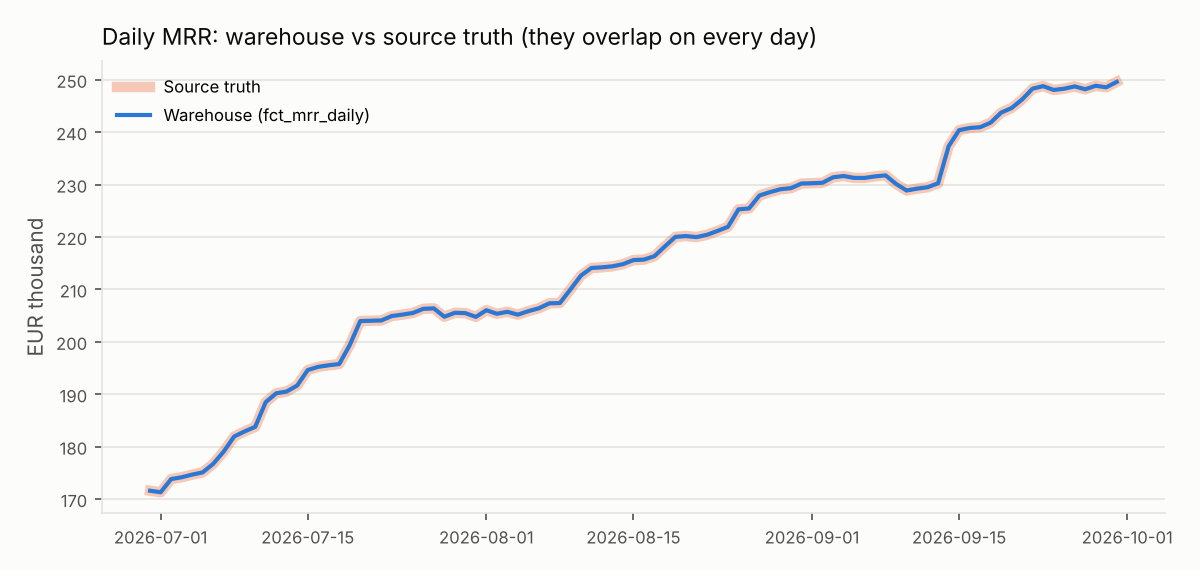

In [5]:
mrr = reporting.mrr_vs_truth(sim)
display(Image(filename=str(reporting.plot_mrr_vs_truth(sim, Path("outputs/figures/mrr_vs_truth.png")))))
print("days with a difference above 1 cent:", int((mrr["difference"].abs() > 0.01).sum()), "of", len(mrr))
usage = reporting.usage_vs_truth(sim)
print("days where usage events differ from delivered events:", int((usage["difference"] != 0).sum()), "of", len(usage))

In [6]:
q("SELECT status, severity, COUNT(*) AS tests FROM meta_test_results GROUP BY 1, 2")

,status,severity,tests
0,pass,error,2760
1,pass,warn,92


## Re-running a day

Each source batch is keyed by run date, so a repeated run skips batches that already succeeded. Row counts and MRR stay the same.

In [7]:
from saas_elt.pipeline import build_dag, load_contracts
before = q("SELECT 'events' AS t, COUNT(*) AS n FROM raw_product_events UNION ALL SELECT 'invoices', COUNT(*) FROM raw_billing_invoices")
dag = build_dag(sim.settings, sim.world, wh, load_contracts(), "2026-06-30")
rerun = dag.run(wh, "2026-09-30", {})
after = q("SELECT 'events' AS t, COUNT(*) AS n FROM raw_product_events UNION ALL SELECT 'invoices', COUNT(*) FROM raw_billing_invoices")
print("rerun status:", rerun.status)
before.merge(after, on="t", suffixes=("_before", "_after"))

rerun status: success


,t,n_before,n_after
0,events,62973,62973
1,invoices,2130,2130


## Privacy controls (GDPR and BDSG)

- Data minimisation: contracts list exactly which fields may land. Unknown fields fail the contract, except where a contract explicitly allows drift.
- Pseudonymisation: users only exist as salted SHA-256 hashes. The salt comes from an environment variable and never sits in the code.
- A PII guard rejects any record with an e-mail address, phone number or IBAN, and masks the value before quarantining it.
- Retention: quarantined records are purged after 90 days.
- Right to erasure (Art. 17): one command deletes a customer from every table and logs only a hash of the ID. Shown below on a copy of the warehouse.

In [8]:
from saas_elt.contracts import load_contract, validate
leaky = {"account_id": "ACC-00001", "company_name": "Nordwerk GmbH", "country": "DE", "industry": "Retail",
         "segment": "SMB", "created_at": "2026-01-01T09:00:00", "updated_at": "2026-01-02T09:00:00",
         "contact_email": "anna.schmidt@example.de"}
res = validate(leaky, load_contract("crm_accounts"))
print(res.ok, res.reasons)
print("stored in quarantine as:", res.safe_record["contact_email"])

False ['pii_detected: email in contact_email', "unexpected_fields: ['contact_email']"]
stored in quarantine as: ***REDACTED***


In [9]:
from saas_elt.warehouse import Warehouse
copy = Path("workdir/erasure_demo.db")
shutil.copy(sim.settings.warehouse_db, copy)
demo = Warehouse(copy)
print("rows deleted:", demo.erase_account("ACC-00042", "DSR-2026-001"))
print("left for ACC-00042 in fct_mrr_daily:", demo.query("SELECT COUNT(*) FROM fct_mrr_daily WHERE account_id='ACC-00042'")[0][0])
pd.read_sql_query("SELECT * FROM meta_erasure_log", demo.conn)

rows deleted: 262
left for ACC-00042 in fct_mrr_daily: 0


,request_id,subject_type,subject_hash,rows_deleted,executed_at
0,DSR-2026-001,account,89aa128fdb0831762c6fdb90680c4be91b0780114547dd46dc1561b6a959b930,262,2026-11-17T20:59:43+00:00
